<a href="https://colab.research.google.com/github/BintangPancahaya/PCVK26_06_BintangPP/blob/main/Week9_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 – Morfologi Citra
**Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi, Polinema**

Nama : Bintang Pancahaya<br>
Kelas : TI-3F

Materi: Erosi, Dilasi, Opening, Closing, Transformasi Top-hat dan Black-hat, Skeleton, Thinning.

## D. Praktikum Morfologi
### Langkah 1 – Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Langkah 2 – Import library

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

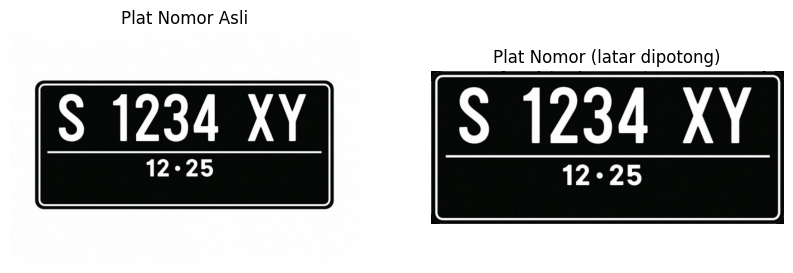

Ukuran asli : (464, 700, 3) -> setelah crop : (259, 599, 3)


In [ ]:
IMG_DIR = '/content/drive/MyDrive/PCVK/Images'

plat_asli = cv2.imread(IMG_DIR + '/plat nomer asli.jpg')
gray = cv2.cvtColor(plat_asli, cv2.COLOR_BGR2GRAY)

# 1. Pisahkan pelat (gelap) dari latar putih
_, mask_gelap = cv2.threshold(gray, 128, 255, cv2.THRESH_BINARY_INV)

# 2. Kontur terbesar = pelat nomor
contours, _ = cv2.findContours(mask_gelap, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
pelat = max(contours, key=cv2.contourArea)
x, y, w, h = cv2.boundingRect(pelat)

# 3. Hitamkan area di luar pelat (sudut membulat), lalu crop
mask = np.zeros(gray.shape, np.uint8)
cv2.drawContours(mask, [pelat], -1, 255, -1)
hasil = plat_asli.copy()
hasil[mask == 0] = 0
plat_crop = hasil[y:y+h, x:x+w]
cv2.imwrite(IMG_DIR + '/plat nomer.jpg', plat_crop)

plt.figure(figsize=(10, 3))
plt.subplot(121), plt.imshow(cv2.cvtColor(plat_asli, cv2.COLOR_BGR2RGB)), plt.title('Plat Nomor Asli'), plt.axis('off')
plt.subplot(122), plt.imshow(cv2.cvtColor(plat_crop, cv2.COLOR_BGR2RGB)), plt.title('Plat Nomor (latar dipotong)'), plt.axis('off')
plt.show()
print('Ukuran asli :', plat_asli.shape, '-> setelah crop :', plat_crop.shape)

### Langkah 3 – Dilasi tanpa library morphology OpenCV

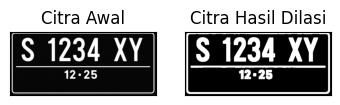

In [ ]:
#Dilasi tanpa library
def dilasi_citra(F,w):
    #size image
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    SED= np.ones((w,w), dtype=np.uint8)
    constant1= (w-1)//2

    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

img_d= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 4 – Dilasi dengan library morphology OpenCV

[[1 1 1]
 [1 1 1]
 [1 1 1]]


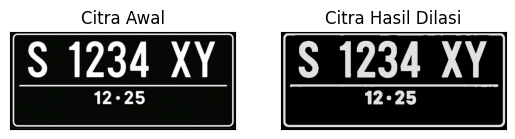

In [ ]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg')
#img = cv2.imread('morp.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)

plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 5 – Erosi tanpa library morphology OpenCV (SE square 5 x 5)

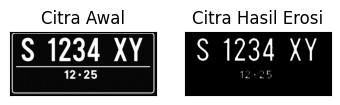

In [ ]:
#Erosi Tanpa Library
def erosi_citra(F,k):
    #size image
    m,n= F.shape

    #Generate structure element erosi (SE)
    SE= np.ones((k,k), dtype=np.uint8)
    constant= (k-1)//2

    imgE= np.zeros((m,n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant, m-constant):
        for j in range(constant,n-constant):
            temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

img_e= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
# Thresholding citra
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k=5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 6 – Erosi dengan library morphology OpenCV (SE square 5 x 5)

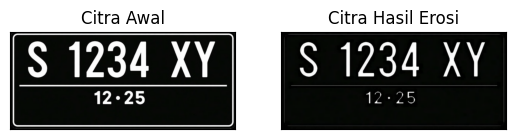

In [ ]:
#EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg')

kernel = np.ones((5,5),np.uint8)
erosion = cv2.erode(img,kernel,iterations = 1)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 7 – Opening tanpa dan dengan library morphology OpenCV
**Operasi Opening tanpa Library Morphology**

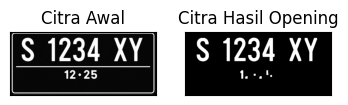

In [ ]:
img_o= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
# Thresholding citra
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k=7
imgO = dilasi_citra(erosi_citra(thresho,k),k)

plt.subplot(131),plt.imshow(img_o,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgO,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

**Operasi Opening dengan Library Morphology**

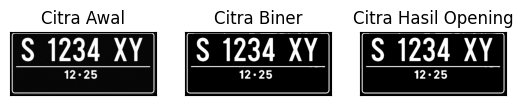

In [ ]:
#Dengan Menggunakan Library
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(openn,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

### Langkah 8 – Closing tanpa dan dengan library morphology OpenCV
**Operasi Closing tanpa Library Morphology**

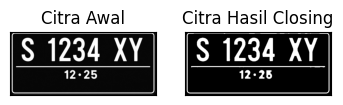

In [ ]:
img_c= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
# Thresholding citra
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k=7
imgC = erosi_citra(dilasi_citra(threshc,k),k)

plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

**Operasi Closing dengan Library Morphology**

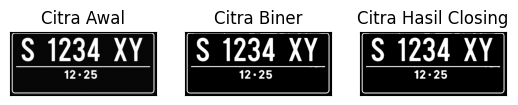

In [ ]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(closs,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.show()

### Langkah 9 – Dilasi dengan SE Cross 3 x 3 dan 5 x 5
**Cross 3**

SED = Cross 3


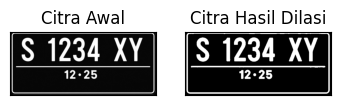

In [ ]:
#Dilasi Cross SED
def dilasi_citra(F,w):
    #size image
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)
    #Generate structure element dilasi (SED)
    # SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype = np.uint8)
    constant1= (w-1)//2

    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

print('SED = Cross 3')
img_d= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w=3
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

**Cross 5**

SED = Cross 5


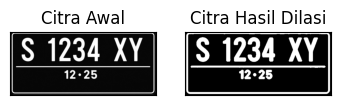

In [ ]:
def dilasi_citra(F,w):
    #size image
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    # SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype = np.uint8)
    constant1= (w-1)//2

    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

print('SED = Cross 5')
img_d= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 10 – Dilasi dengan SE Circular 3 x 3 dan 5 x 5
**Circle 3**

SED = Circle 3


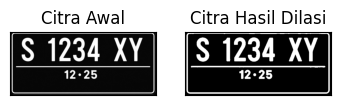

In [ ]:
#Dilasi Circular SED
def dilasi_citra(F,w):
    #size image
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
    constant1= (w-1)//2

    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

print('SED = Circle 3')
img_d= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w=3
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

**Circle 5**

SED = Circle 5


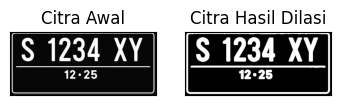

In [ ]:
print('SED = Circle 5')
img_d= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 11 – Erosi dengan SE Rectangle 3 x 5 dan 5 x 7
**Rectangle 3x5**

SE = Rectangle 3x5


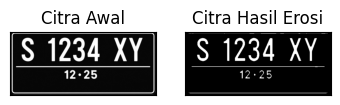

In [ ]:
#Erosi Rectangle SE
def erosi_citra(F,p,l):
    #size image
    m,n= F.shape

    #Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l)) #SE persegi panjang
    constant1= (l-1)//2
    constant2= (p-1)//2
    # print(SE)
    imgE= np.zeros((m,n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant1, m-constant1):
        for j in range(constant2,n-constant2):
            temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

print('SE = Rectangle 3x5')
img_e= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
# Thresholding citra
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p=5
l=3
imgE = erosi_citra(thresh1,p,l)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

**Rectangle 5x7**

SE = Rectangle 5x7


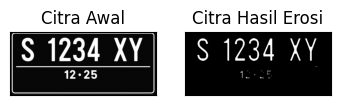

In [ ]:
print('SE = Rectangle 5x7')
img_e= cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg',0)
# Thresholding citra
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p=7
l=5
imgE = erosi_citra(thresh1,p,l)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 12 – Erosi dengan SE Line Vertikal 3 dan 5 (citra `j.png`)
Catatan: sesuai instruksi modul, citra yang dipakai adalah `j.png`. Potongan citra (`temp`) diambil selebar 1 kolom
agar ukurannya sama dengan SE garis vertikal (k x 1). Jika `temp` tetap k x k, perkalian `temp*SE` di-*broadcast*
sehingga hasilnya sama dengan erosi square, bukan line vertikal.

**Line Vertikal 3**

SE = Line Vertikal 3


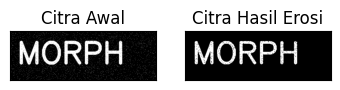

In [ ]:
#Erosi Line Vertikal SE
def erosi_citra(F,k):
    #size image
    m,n= F.shape

    #Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k)) #SE line vertikal (k baris x 1 kolom)
    constant= (k-1)//2

    imgE= np.zeros((m,n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant, m-constant):
        for j in range(n):
            temp= F[i-constant:i+constant+1, j:j+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

print('SE = Line Vertikal 3')
img_e= cv2.imread('/content/drive/MyDrive/PCVK/Images/j.png',0)
# Thresholding citra
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k=3
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

**Line Vertikal 5**

SE = Line Vertikal 5


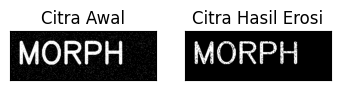

In [ ]:
print('SE = Line Vertikal 5')
img_e= cv2.imread('/content/drive/MyDrive/PCVK/Images/j.png',0)
# Thresholding citra
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k=5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 13 – Transformasi Top-hat (SE 3 x 3)
Catatan: pada modul, `cv2.morphologyEx` memakai variabel `input_image` yang tidak pernah didefinisikan,
jadi diganti dengan `img` (citra grayscale yang sudah dibaca).

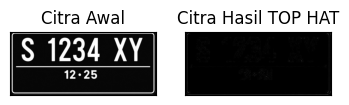

Top-hat OpenCV == f - opening(f) : True


In [ ]:
# Getting the kernel to be used in Top-Hat
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,
                                   filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img,
                              cv2.MORPH_TOPHAT, kernel)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

# Verifikasi rumus: Top-hat = f - opening(f)
manual_tophat = cv2.subtract(img, cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel))
print('Top-hat OpenCV == f - opening(f) :', np.array_equal(tophat_img, manual_tophat))

### Langkah 14 – Transformasi Black-hat (SE 3 x 3)
Kode modul membuat kernel 3 x 3, tetapi yang dipakai pada `MORPH_BLACKHAT` adalah `Kernel` berukuran 13 x 5.
Di bawah ini kode modul tetap dijalankan, lalu ditambah hasil dengan SE 3 x 3 sesuai instruksi soal dan verifikasi
bahwa Black-hat = closing − citra asal.

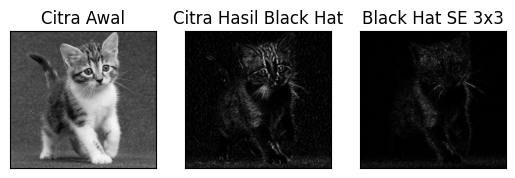

Black-hat OpenCV == closing(f) - f : True
Jika dibalik, f - closing(f) -> nilai maksimum = 0


In [ ]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,
                                   filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])

# Black-hat dengan SE 3 x 3 (sesuai instruksi soal)
blackhat3 = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)
plt.subplot(133),plt.imshow(blackhat3,cmap = 'gray')
plt.title('Black Hat SE 3x3'), plt.xticks([]), plt.yticks([])
plt.show()

# Verifikasi rumus: Black-hat = closing(f) - f   (urutan pengurangan tidak boleh terbalik)
closing3 = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel)
print('Black-hat OpenCV == closing(f) - f :', np.array_equal(blackhat3, cv2.subtract(closing3, img)))
print('Jika dibalik, f - closing(f) -> nilai maksimum =', cv2.subtract(img, closing3).max())

### Langkah 15 – Skeleton pada citra biner

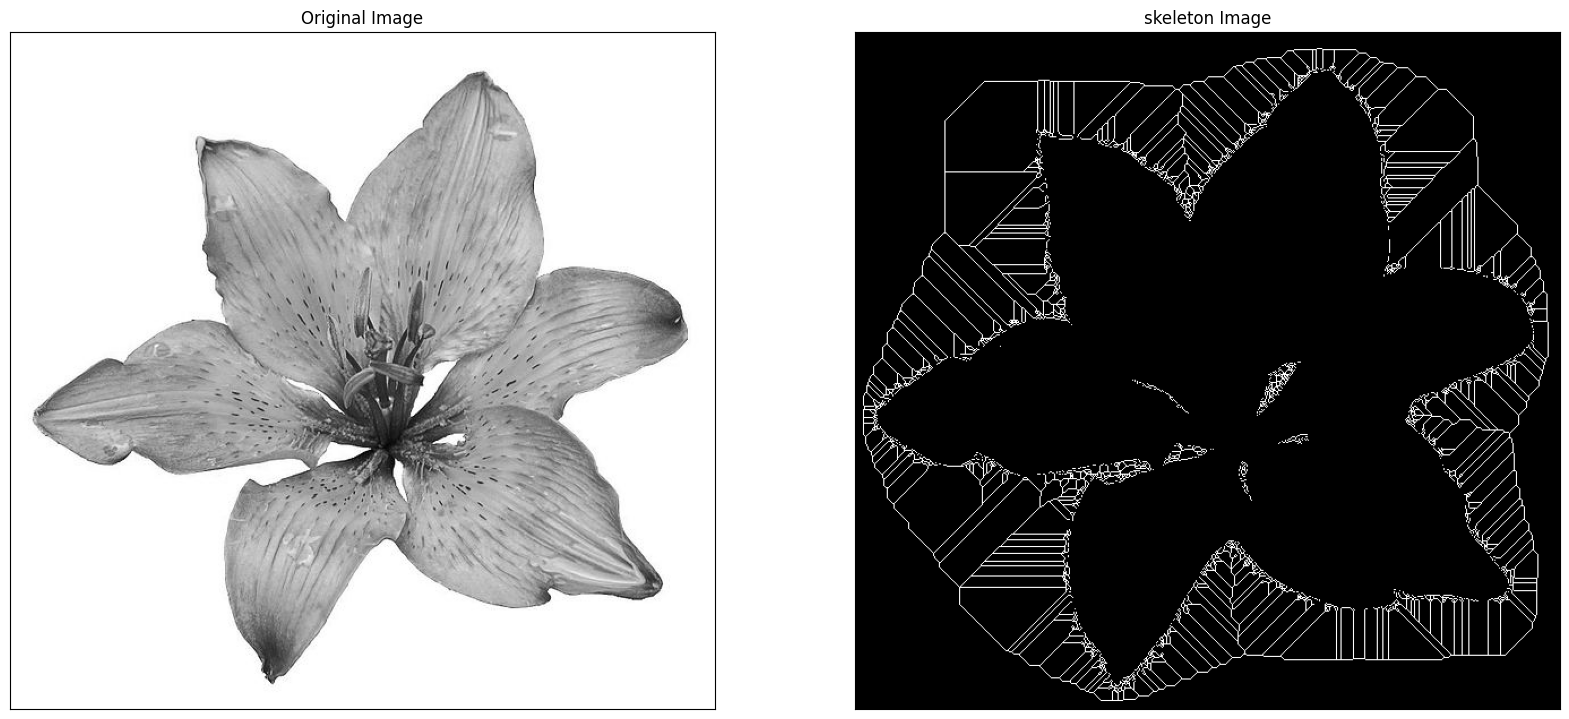

In [ ]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg',0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))

plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

### Langkah 16 – Skeleton pada citra hasil inversi

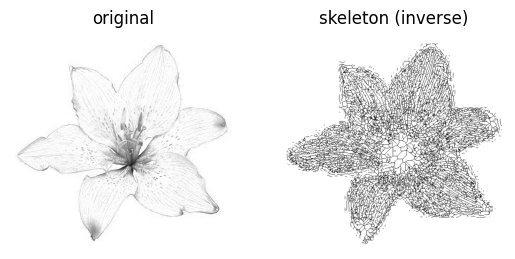

In [ ]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

**Perbandingan dengan langkah 15**

In [ ]:
# Perbandingan jumlah piksel objek dan piksel rangka langkah 15 vs langkah 16
img15 = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg',0)
bin15 = img15 > filters.threshold_triangle(img15)
skel15 = skeletonize(bin15)

print('Langkah 15 (objek terang)  : piksel objek =', bin15.sum(), '| piksel skeleton =', skel15.sum())
print('Langkah 16 (objek gelap)   : piksel objek =', binary.sum(), '| piksel skeleton =', skeleton.sum())

Langkah 15 (objek terang)  : piksel objek = 212716 | piksel skeleton = 15477
Langkah 16 (objek gelap)   : piksel objek = 114192 | piksel skeleton = 45111


**Jawaban:**

Pada langkah 15, citra lily dibinerkan dengan `img > threshold_triangle(img)`, sehingga piksel yang dianggap objek (True) adalah piksel terang, yaitu **latar belakang putih** di sekeliling bunga (212.716 piksel). Akibatnya skeleton langkah 15 (15.477 piksel) adalah rangka dari latar: berupa garis-garis di luar bunga yang mengikuti kontur kelopak, sedangkan bunganya sendiri tampil hitam (kosong).

Pada langkah 16 operatornya dibalik menjadi `img < threshold_triangle(img)` (citra hasil inversi), sehingga objeknya menjadi piksel gelap, yaitu **tekstur, urat, dan bintik pada kelopak bunga** (114.192 piksel). Skeleton yang dihasilkan (45.111 piksel) berada di dalam bentuk bunga dan jauh lebih rapat, karena teksturnya terdiri dari banyak bagian kecil yang masing-masing punya rangka sendiri. Hasilnya ditampilkan dengan colormap `gray_r`, jadi rangka tampak hitam di atas latar putih. Selain itu, langkah 16 hanya memakai kanal pertama (R) `[..., 0]`, bukan grayscale seperti langkah 15, sehingga nilai threshold-nya juga berbeda.

Kesimpulannya, skeletonisasi selalu dikerjakan pada piksel bernilai True, jadi pemilihan `>` atau `<` saat thresholding menentukan bagian mana yang dirangka. Untuk citra bunga ini, versi inversi (langkah 16) yang menghasilkan rangka dari bunganya, sedangkan langkah 15 menghasilkan rangka dari latarnya.

### Langkah 17 – Thinning dengan `morphology.thin()`

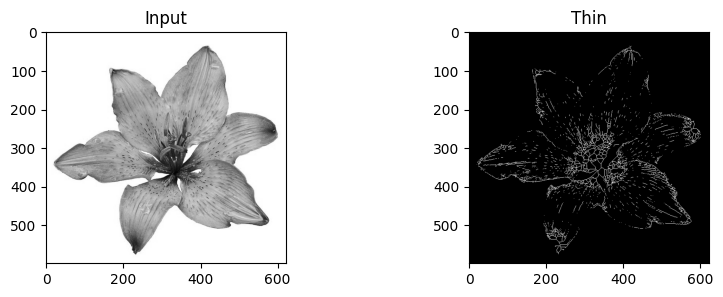

In [ ]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')))

image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

**Perbandingan thinning dengan skeleton**

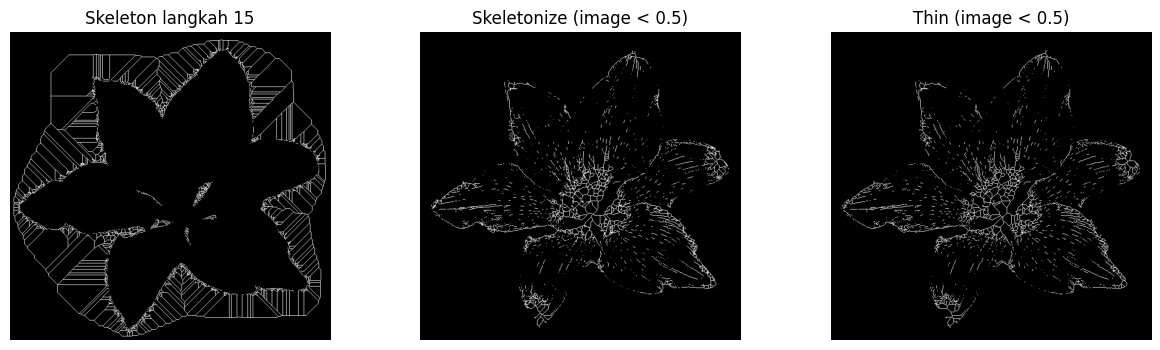

Piksel skeleton langkah 15 : 15477
Piksel skeletonize         : 10305
Piksel thin                : 10280
Piksel berbeda (skeletonize vs thin): 5487


In [ ]:
# Bandingkan hasil thin() dengan skeletonize() pada citra biner yang sama,
# serta dengan skeleton langkah 15
f, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(skel15, cmap='gray');          ax[0].set_title('Skeleton langkah 15')
ax[1].imshow(out_skeletonize, cmap='gray'); ax[1].set_title('Skeletonize (image < 0.5)')
ax[2].imshow(out_thin, cmap='gray');        ax[2].set_title('Thin (image < 0.5)')
for a in ax: a.set_axis_off()
plt.show()

print('Piksel skeleton langkah 15 :', skel15.sum())
print('Piksel skeletonize         :', out_skeletonize.sum())
print('Piksel thin                :', out_thin.sum())
print('Piksel berbeda (skeletonize vs thin):', np.logical_xor(out_skeletonize, out_thin).sum())

**Jawaban:**

Pada citra biner yang sama (`image < 0.5`, objek = bagian gelap pada kelopak), hasil `thin()` dan `skeletonize()` terlihat sangat mirip: keduanya mengubah objek menjadi garis setebal 1 piksel yang tetap mempertahankan keterhubungan (topologi) objek. Jumlah pikselnya hampir sama (skeletonize 10.305 piksel, thin 10.280 piksel), tetapi posisi garisnya tidak identik (5.487 piksel berbeda). Perbedaan ini muncul karena algoritmanya berbeda: `skeletonize()` (Zhang–Suen) mencari garis tengah (*medial axis*) objek, sedangkan `thin()` (Guo–Hall) mengikis piksel tepi lapis demi lapis berbasis *hit-or-miss*, A ⊗ B = A − (A ⊛ B), sampai tidak ada lagi perubahan. Akibatnya hasil thin sedikit lebih ramping dan garisnya bergeser 1 piksel di beberapa tempat.

Dibandingkan dengan skeleton langkah 15 (15.477 piksel), perbedaannya jauh lebih besar: skeleton langkah 15 adalah rangka dari latar putih di luar bunga (karena memakai `img > threshold`), sedangkan hasil thin langkah 17 adalah rangka dari tekstur gelap di dalam bunga. Jadi perbedaan utama antara langkah 15 dan 17 berasal dari pemilihan objek saat thresholding, sedangkan perbedaan antara thin dan skeletonize kecil dan berasal dari algoritmanya.